The first example leveraging Universes.

MCNP use the "5 like 2 but trcl=3" construct, which basically means that cell 5 is like cell 2 but the applied transformation is, instead, TR3.

(edit) having looked into the github issues regarding rotation in OpenMC, apparently one needs to be careful about attempting to apply rotations and translations to ZCylinders and other axially-aligned objects. 

Generally not recommended to specify manual cell_ids

Trying to use rotation matrix vis-a-vis MCNP leads to bad results for some reason.

In [ ]:
import openmc
import numpy as np

materials=openmc.Materials()

carbon = openmc.Material()
carbon.add_nuclide('C6',1)

materials.append(carbon)
uranium = openmc.Material()
uranium.add_nuclide('U235',1)

materials.append(uranium)

In [1]:
import openmc as openmc

# Surface definitions
s1 = openmc.XPlane(-3)
s2 = openmc.XPlane(3)
s3 = openmc.YPlane(3)
s4 = openmc.YPlane(-3)
s5 = openmc.ZPlane(4.7)
s6 = openmc.ZPlane(-4.7)

s10 = openmc.ZCylinder(r=1)
s11 = openmc.ZPlane(4.5)
s12 = openmc.ZPlane(-4.5)

#boundary_type=vacuum analagous to imp:n=0
s27 = openmc.Sphere(x0=3.5, y0=3.5, z0=0, r=11, boundary_type='vacuum') 



In [2]:
# Cell definitions
c3 = openmc.Cell(fill=None,region=(-s10 & -s11 & +s12))
c4 = openmc.Cell(fill=None,region=(~c3.region))
u1 = openmc.Universe()
u1.add_cells([c3,c4])

c2 = openmc.Cell( fill=u1, region=(+s1 & -s2 & -s3 & +s4 & -s5 & +s6)) #cell 2 is centered on the origin. 
# if you drag c2 to somewhere else, like so:
# c2.region = c2.region.translate((-1,0,0))
# you will need to manually apply the same translation to the filled universe:
# c2.translation = (-1,0,0)
# and then also be careful if you are using this definition of c2.region later on because this will have knock-on effects

# 5 like 2 but trcl=3
c5 = openmc.Cell()
c5.region = c2.region.rotate([0,0,50]).translate((7,7,0)) # cell 5 is NOT centered on the origin. 
c5.fill = u1

#print(c3.num_instances)

#c5.region = c2.region.translate((7,7,0))
#c5.region = c5.region.rotate([[40,130,90],[50,40,90],[90,90,0]],pivot=(7,7,0))
# Bad things happen when you try to rotate the region because the "Z-cylinder" is no longer a Z-cylinder [THIS IS NOT TRUE]
# (see issues #2909 and #3248) 

c5.translation = (7,7,0)
# So the .translation property tells OpenMC where you need to drag the filled universe. In other words,
# specifying "c5.region = c2.region.rotate([0,0,45]).translate((7,7,0))" does NOT recursively apply to the filled
# universe, regardless of the order.

c1 = openmc.Cell( fill=None,region=(-s27 & ~c2.region & ~c5.region))
c7 = openmc.Cell( fill=None,region=+s27)

geometry = openmc.Geometry([c1,c2,c3,c4,c5,c7])

settings = openmc.Settings()


materials.export_to_xml()

w = 25
plots = openmc.Plots()

level = 1
plot = openmc.SlicePlot()
plot.basis = 'xy'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
#plot.level=level
plots.append(plot)

plot = openmc.SlicePlot()
plot.basis = 'xz'
plot.origin = (0.0, 7.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
#plot.level=level
plots.append(plot)

plot = openmc.SlicePlot()
plot.basis = 'yz'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
#plot.level = level
plots.append(plot)

model = openmc.model.Model()
model.geometry=geometry
model.materials=materials
model.settings=settings
model.export_to_xml()


/home/jovibuca/endf/endfb-viii.0-hdf5/cross_sections.xml


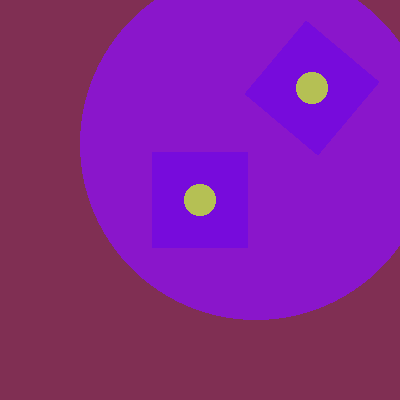

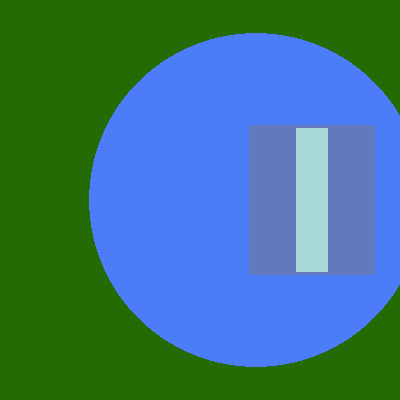

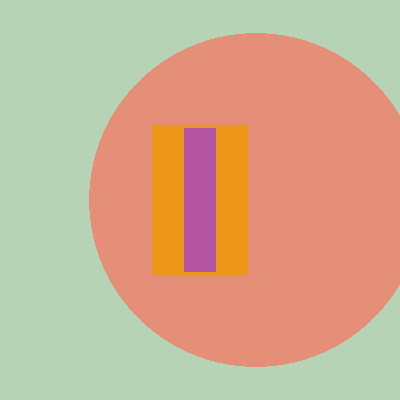

In [3]:
openmc.plot_inline(plots)